# Restarting a Failed Graph

In [1]:
from typing import TypedDict, Optional, NotRequired, Annotated
from langgraph.graph import StateGraph, START, END
from operator import add

Langgraph can checkpoint the state of the graph at each step/node traversed

InMemorySaver checkpoints the state in-memory

Other Options include saving the state into a persistent database store

In [2]:
from langgraph.checkpoint.memory import InMemorySaver

## Define the Graph

In [3]:
class AppState(TypedDict):
    is_api_1_down: bool
    is_api_2_down: bool
    logs: Annotated[Optional[list['str']], add]

In [4]:
def step_one(state: AppState):
    if state.get('is_api_1_down'):
        raise ConnectionError('Remote API Down')

    return {
        'logs': ['Step 1 Completed']
    }

def step_two(state: AppState):
    if state.get('is_api_2_down'):
        raise ConnectionError('Remote API Down')

    return {
        'logs': ['Step 2 Completed']
    }

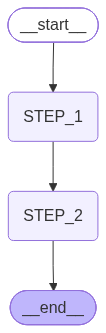

In [5]:
builder = StateGraph(AppState)

builder.add_node('STEP_1', step_one)
builder.add_node('STEP_2', step_two)

builder.add_edge(START, 'STEP_1')
builder.add_edge('STEP_1', 'STEP_2')
builder.add_edge('STEP_2', END)

checkpointer = InMemorySaver()

graph = builder.compile(checkpointer=checkpointer)
graph

## Invoke the graph

Use config to identify a specific execution session (like a chat session of a unique request id)

In [6]:
initial_state = {
    'is_api_1_down' : False,
    'is_api_2_down' : False,
}

config = {"configurable": {"thread_id": "request_1"}}
print(graph.invoke(initial_state, config=config))

{'is_api_1_down': False, 'is_api_2_down': False, 'logs': ['Step 1 Completed', 'Step 2 Completed']}


In [7]:
graph.get_state(config=config)

StateSnapshot(values={'is_api_1_down': False, 'is_api_2_down': False, 'logs': ['Step 1 Completed', 'Step 2 Completed']}, next=(), config={'configurable': {'thread_id': 'request_1', 'checkpoint_ns': '', 'checkpoint_id': '1f1ccb36-09fe-6812-8002-52948db4883e'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-20T18:23:41.750059+00:00', parent_config={'configurable': {'thread_id': 'request_1', 'checkpoint_ns': '', 'checkpoint_id': '1f1ccb36-09fd-626e-8001-d1d0cfc16046'}}, tasks=(), interrupts=())

In [8]:
for h in graph.get_state_history(config=config):
    print(h, '\n')

StateSnapshot(values={'is_api_1_down': False, 'is_api_2_down': False, 'logs': ['Step 1 Completed', 'Step 2 Completed']}, next=(), config={'configurable': {'thread_id': 'request_1', 'checkpoint_ns': '', 'checkpoint_id': '1f1ccb36-09fe-6812-8002-52948db4883e'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-20T18:23:41.750059+00:00', parent_config={'configurable': {'thread_id': 'request_1', 'checkpoint_ns': '', 'checkpoint_id': '1f1ccb36-09fd-626e-8001-d1d0cfc16046'}}, tasks=(), interrupts=()) 

StateSnapshot(values={'is_api_1_down': False, 'is_api_2_down': False, 'logs': ['Step 1 Completed']}, next=('STEP_2',), config={'configurable': {'thread_id': 'request_1', 'checkpoint_ns': '', 'checkpoint_id': '1f1ccb36-09fd-626e-8001-d1d0cfc16046'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-20T18:23:41.749504+00:00', parent_config={'configurable': {'thread_id': 'request_1', 'checkpoint_ns': '', 'checkpoint_id': '1f1ccb36-09fb-6608-8000

### Let us simulate an error

In [9]:
initial_state = {
    'is_api_1_down' : False,
    'is_api_2_down' : True,
}

config = {"configurable": {"thread_id": "request_2"}}

try:
    graph.invoke(initial_state, config=config)
except Exception as e:
    print(e)

Remote API Down


In [10]:
graph.get_state(config=config)

StateSnapshot(values={'is_api_1_down': False, 'is_api_2_down': True, 'logs': ['Step 1 Completed']}, next=('STEP_2',), config={'configurable': {'thread_id': 'request_2', 'checkpoint_ns': '', 'checkpoint_id': '1f1ccb36-0a2b-6aa6-8001-38ed9cba0458'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-20T18:23:41.768558+00:00', parent_config={'configurable': {'thread_id': 'request_2', 'checkpoint_ns': '', 'checkpoint_id': '1f1ccb36-0a2a-62a0-8000-68a5ab4e4500'}}, tasks=(PregelTask(id='c83d80fb-8994-ce84-b6a8-c869133469ec', name='STEP_2', path=('__pregel_pull', 'STEP_2'), error="ConnectionError('Remote API Down')", interrupts=(), state=None, result=None),), interrupts=())

In [11]:
for h in graph.get_state_history(config=config):
    print(h, '\n')

StateSnapshot(values={'is_api_1_down': False, 'is_api_2_down': True, 'logs': ['Step 1 Completed']}, next=('STEP_2',), config={'configurable': {'thread_id': 'request_2', 'checkpoint_ns': '', 'checkpoint_id': '1f1ccb36-0a2b-6aa6-8001-38ed9cba0458'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-20T18:23:41.768558+00:00', parent_config={'configurable': {'thread_id': 'request_2', 'checkpoint_ns': '', 'checkpoint_id': '1f1ccb36-0a2a-62a0-8000-68a5ab4e4500'}}, tasks=(PregelTask(id='c83d80fb-8994-ce84-b6a8-c869133469ec', name='STEP_2', path=('__pregel_pull', 'STEP_2'), error="ConnectionError('Remote API Down')", interrupts=(), state=None, result=None),), interrupts=()) 

StateSnapshot(values={'is_api_1_down': False, 'is_api_2_down': True}, next=('STEP_1',), config={'configurable': {'thread_id': 'request_2', 'checkpoint_ns': '', 'checkpoint_id': '1f1ccb36-0a2a-62a0-8000-68a5ab4e4500'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-20T

### Update the state and restart the graph from where it left off

In [12]:
graph.update_state(config=config, values={'is_api_2_down': False})

graph.invoke(None, config=config)

{'is_api_1_down': False,
 'is_api_2_down': False,
 'logs': ['Step 1 Completed', 'Step 2 Completed']}

In [13]:
graph.update_state(config=config, values=None, as_node=START)

graph.invoke(None, config=config)

{'is_api_1_down': False,
 'is_api_2_down': False,
 'logs': ['Step 1 Completed',
  'Step 2 Completed',
  'Step 1 Completed',
  'Step 2 Completed']}